# AMAZON STOCK PRICE ANALYSIS

![Screen%20Shot%202022-11-11%20at%2023.25.33.png](attachment:Screen%20Shot%202022-11-11%20at%2023.25.33.png)

## INTRODUCTION

This project attempts to forecast the stock from Amazon and adding important US economic features such as GDP, Monthly Retail Trade, CPI and Inflation rate. There are two notebooks for this project. The first one is where the dataset was created. The second one is where the deep analysis takes place

The data was collected from the following resources:

* [Yahoo Finances](https://finance.yahoo.com/quote/EBAY?p=EBAY&.tsrc=fin-srch) Amazon stock data from May 1997 to Nov 2022. To check the historic data of Amazon stock
* [GDP](https://data.worldbank.org/indicator/NY.GDP.MKTP.CD) Check the GDP of US. The GDP is a highly important indicator on a country's economy
* [Monthly Retail Trade](https://www.census.gov/retail/mrts/www/benchmark/2022/html/annrev22.html) I thought it would be interesting to check the biggest online retail store agains physical stores

#### CPI and Inflation Rate are highly correlated. Inflation Rate is calculated by the difference on CPI indexes
* [CPI for All Urban Consumers (CPI-U)](https://beta.bls.gov/dataViewer/view/timeseries/CUSR0000SA0)
* [Inflation Rate](https://www.usinflationcalculator.com/inflation/historical-inflation-rates/#google_vignette)


* Unemployment rate [U.S. BUREAU OF LABOR STATISTICS](https://data.bls.gov/pdq/SurveyOutputServlet) Unemployment rate is important to look at to know the spending nature of consumers

All data was cleaned and merged to become one dataset.

## DATA IMPORTING and Exploration

In [ ]:
import pandas as pd
import datetime
import numpy as np
import matplotlib.pyplot as plt
from pandas.plotting import scatter_matrix
%matplotlib inline
# !pip install yfinance
import yfinance as yf


In [ ]:
start = "1997-05-15"
end = '2022-11-10'
amzn = yf.download('AMZN',start,end)
ebay = yf.download('EBAY',start,end)

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


The daily stock prices for Amazon and Ebay have been downloaded using the Yahoo finance API functionality. Data has been downloaded since May 15 1997 which was the year that Amazon went public. To make a quick comparison, the data for Ebay was also downloaded. Ebay is Amazons major competitor and the company went public in Sep 24 1998 which gives us a good range of data for both companies.  

Open, High, Low, Close, and Volume

Open: The price of the stock when the market opens in the morning
Close: The price of the stock when the market closed in the evening
High: Highest price the stock reached during that day
Low: Lowest price the stock is traded on that day
Volume: The total amount of stocks traded on that day

In [ ]:
amzn.head(20)

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
1997-05-15,0.121875,0.125000,0.096354,0.097917,0.097917,1443120000
1997-05-16,0.098438,0.098958,0.085417,0.086458,0.086458,294000000
1997-05-19,0.088021,0.088542,0.081250,0.085417,0.085417,122136000
1997-05-20,0.086458,0.087500,0.081771,0.081771,0.081771,109344000
1997-05-21,0.081771,0.082292,0.068750,0.071354,0.071354,377064000
1997-05-22,0.071875,0.072396,0.065625,0.069792,0.069792,235536000
1997-05-23,0.070313,0.076042,0.066667,0.075000,0.075000,318744000
1997-05-27,0.075521,0.082292,0.072917,0.079167,0.079167,173952000
1997-05-28,0.081250,0.081771,0.076563,0.076563,0.076563,91488000


Let's look at the Amazon stock more closely

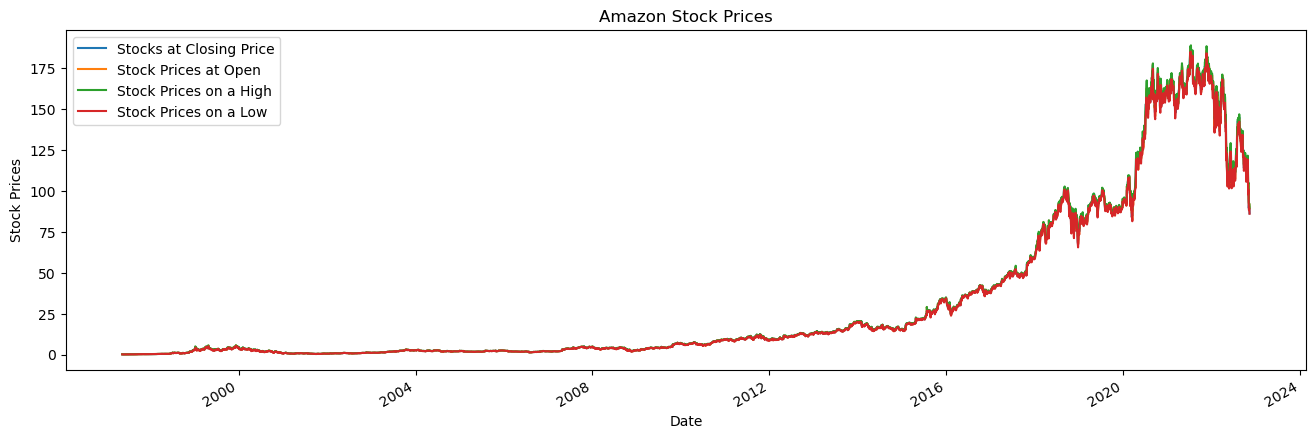

In [ ]:
amzn['Close'].plot(label = 'Stocks at Closing Price', figsize = (16,5))
amzn['Open'].plot(label = 'Stock Prices at Open')
amzn['High'].plot(label = 'Stock Prices on a High')
amzn['Low'].plot(label = 'Stock Prices on a Low')
plt.legend()
plt.title ('Amazon Stock Prices')
plt.ylabel('Stock Prices')
plt.show()



We see a big spike in their stocks after 2020, which was a detrimental year on the economy of most countries and industries.  

###  Amazon SWOT Analysis
A quick analysis between Amazon and their biggest competitor Ebay will be done next.

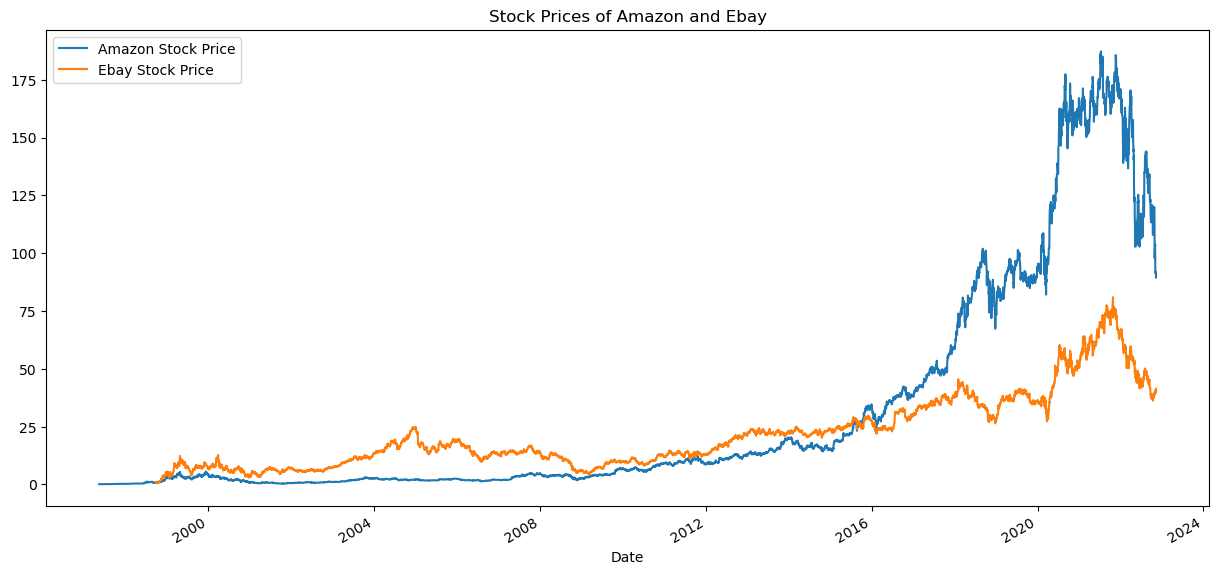

In [ ]:
amzn['Open'].plot(label = 'Amazon Stock Price', figsize = (15,7))
ebay['Open'].plot(label = "Ebay Stock Price")
plt.title('Stock Prices of Amazon and Ebay')
plt.legend();

The graph  above, shows the a YOY over year comparison between conmpanies. However this graph does not provide an accurate comparison between companies. To get a more accurate representation, a new variable will be introduced, the market capitalization which shows which company is more valuable than the other. The market cap is derived from multiplying the volume of the stock with the open price.

#### Market Capitalisation

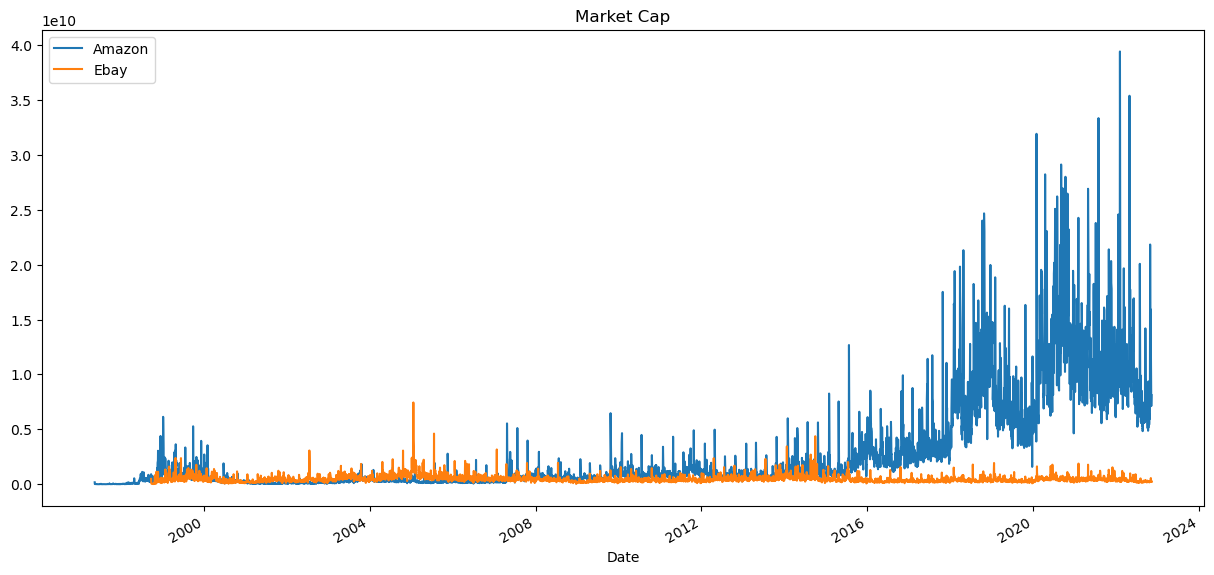

In [ ]:
amzn['MarktCap'] = amzn['Open'] * amzn['Volume']
ebay['MarktCap'] = ebay['Open'] * ebay['Volume']
amzn['MarktCap'].plot(label = 'Amazon', figsize = (15,7))
ebay['MarktCap'].plot(label = 'Ebay')
plt.title('Market Cap')
plt.legend();

As we can clearly see from the graph that Amazon has traded on the higher side.

#### Moving Averages

Stock prices are highly volatile and prices change quickly with time. To observe any trend or pattern  a 50-day 200-day average will be used.

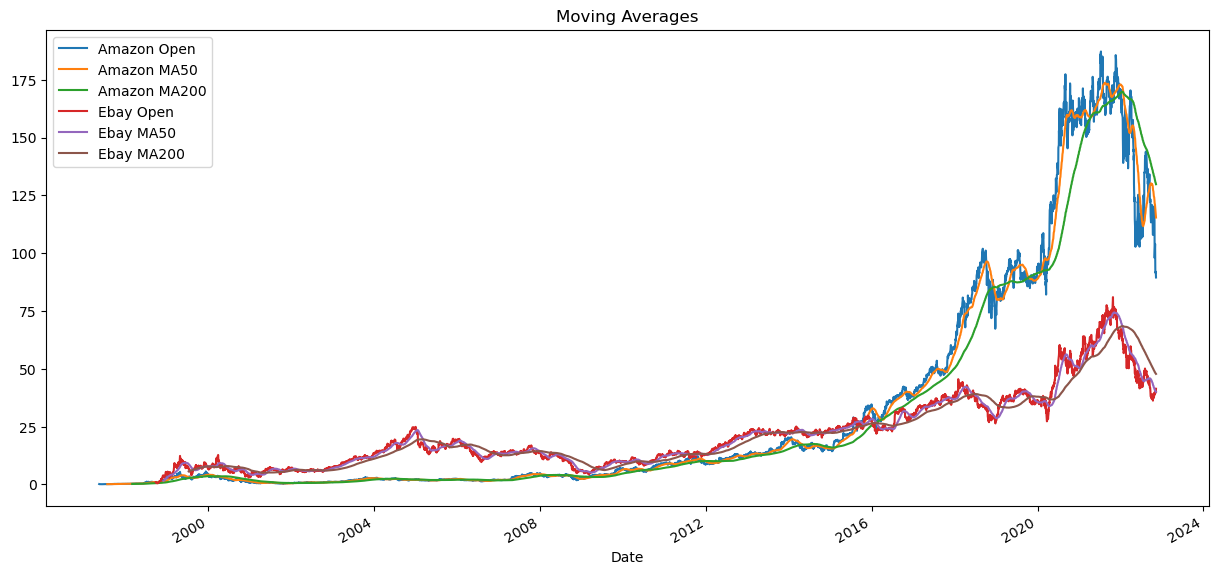

In [ ]:

amzn['MA50'] = amzn['Open'].rolling(50).mean()
amzn['MA200'] = amzn['Open'].rolling(200).mean()
amzn['Open'].plot(figsize = (15,7), label = 'Amazon Open')
amzn['MA50'].plot(label = 'Amazon MA50')
amzn['MA200'].plot(label = 'Amazon MA200')
ebay['MA50'] = ebay['Open'].rolling(50).mean()
ebay['MA200'] = ebay['Open'].rolling(200).mean()
ebay['Open'].plot(figsize = (15,7),label = 'Ebay Open')
ebay['MA50'].plot(label = 'Ebay MA50')
ebay['MA200'].plot(label = 'Ebay MA200')
plt.title('Moving Averages')
plt.legend();

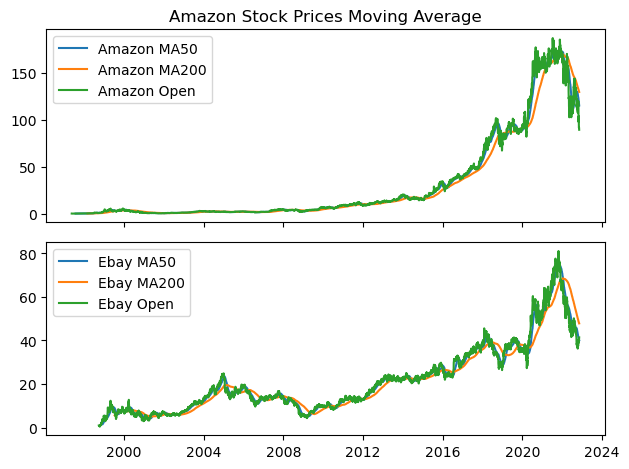

In [ ]:
amznma50 = amzn['Open'].rolling(50).mean()
amznma200 = amzn['Open'].rolling(200).mean()
amznopen = amzn['Open']
ebayma50 = ebay['Open'].rolling(50).mean()
ebayma200 = ebay['Open'].rolling(200).mean()
ebayopen = ebay['Open']

fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, sharex = True)

ax1.plot(amznma50, label ='Amazon MA50')
ax1.plot(amznma200,label = 'Amazon MA200')
ax1.plot(amznopen, label = 'Amazon Open')

ax2.plot(ebayma50, label ='Ebay MA50')
ax2.plot(ebayma200,label = 'Ebay MA200')
ax2.plot(ebayopen, label = 'Ebay Open')


ax1.legend()
ax1.set_title('Amazon Stock Prices Moving Average')


ax2.legend()



plt.tight_layout();



From this graphs we can see how the stock prices between Amazon and Ebay have changed. Also we can see that before 2016 Ebay had a higher moving average than Amazon, after 2016 you see the drop on Ebay and an exponential rise in Amazon stock price

#### Percentage increase in stock value

Last for the Amazon SWOT analysis we will look at the percentage increase ins tock value which is the change in stock comparing that to the previous day. This percentage will highly impact how volatile the stock is.

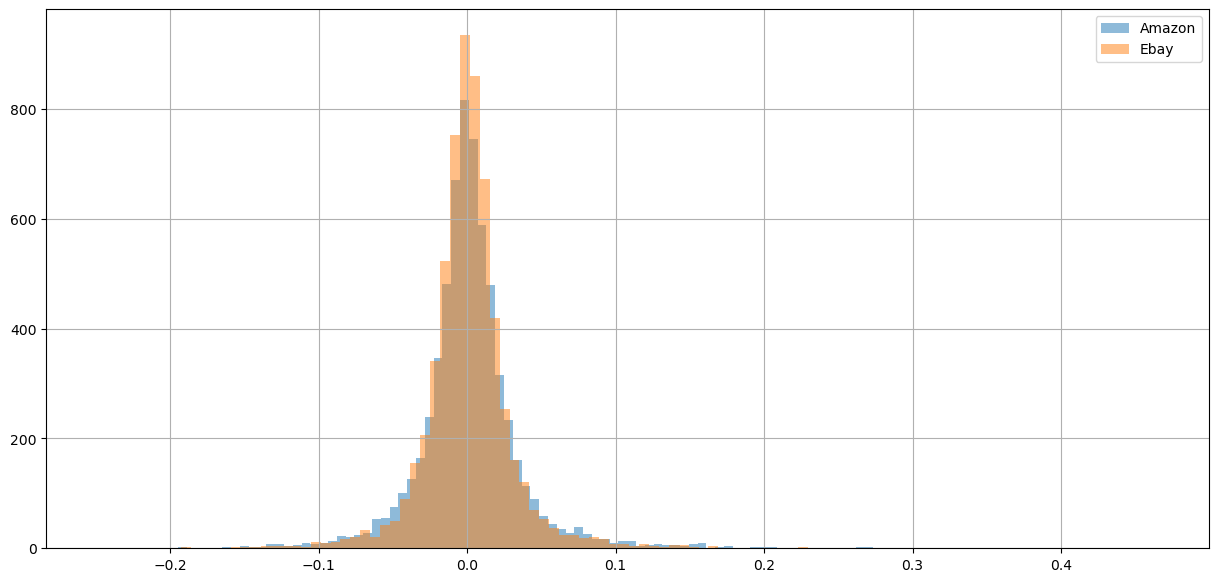

In [ ]:
#Volatility
amzn['returns'] = (amzn['Close']/amzn['Close'].shift(1)) -1
ebay['returns'] = (ebay['Close']/ebay['Close'].shift(1))-1
amzn['returns'].hist(bins = 100, label = 'Amazon', alpha = 0.5, figsize = (15,7))
ebay['returns'].hist(bins = 100, label = 'Ebay', alpha = 0.5)
plt.legend();

It is clear from the graph that the percentage increase in stock price histogram for Ebay is the widest which indicates the stock of Ebay is the most volatile among the two companies.

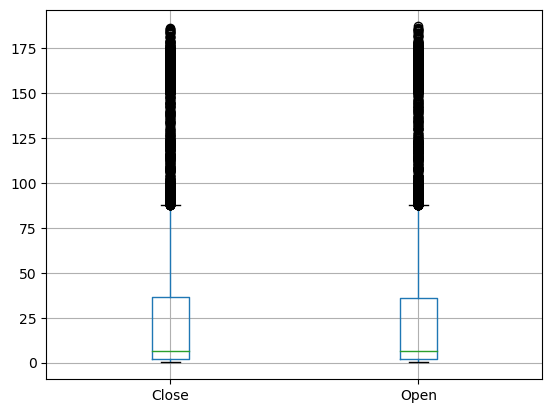

In [ ]:
amzn.boxplot(column=['Close','Open']);

### US marking indicators

To better understand the data we will add some US marking indicators to our Amazon dataset. We will add US GDP, US inflation, US CPI,US retail and food revenue and US unemployment. All datasets will be standarized to be merged later one

#### GDP

GDP (Gross domestic product) measures the value of the final goods and services produced in each country.

In [ ]:
gdp = pd.read_csv('API_NY.GDP.MKTP.CD_DS2_en_csv_v2_4701247.csv', skiprows=3)

In [ ]:
gdp.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2013,2014,2015,2016,2017,2018,2019,2020,2021,Unnamed: 66
0,Aruba,ABW,GDP (current US$),NY.GDP.MKTP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,2.727933e+09,2.791061e+09,2.963128e+09,2.983799e+09,3.092179e+09,3.202235e+09,3.310056e+09,2.496648e+09,NaN,NaN
1,Africa Eastern and Southern,AFE,GDP (current US$),NY.GDP.MKTP.CD,2.129059e+10,2.180847e+10,2.370702e+10,2.821004e+10,2.611879e+10,2.968217e+10,...,9.839370e+11,1.003679e+12,9.242525e+11,8.823551e+11,1.020647e+12,9.910223e+11,9.975340e+11,9.216459e+11,1.082096e+12,NaN
2,Afghanistan,AFG,GDP (current US$),NY.GDP.MKTP.CD,5.377778e+08,5.488889e+08,5.466667e+08,7.511112e+08,8.000000e+08,1.006667e+09,...,2.014640e+10,2.049713e+10,1.913421e+10,1.811656e+10,1.875347e+10,1.805323e+10,1.879945e+10,2.011614e+10,NaN,NaN
3,Africa Western and Central,AFW,GDP (current US$),NY.GDP.MKTP.CD,1.040414e+10,1.112789e+10,1.194319e+10,1.267633e+10,1.383837e+10,1.486223e+10,...,8.207927e+11,8.649905e+11,7.607345e+11,6.905464e+11,6.837487e+11,7.416899e+11,7.945430e+11,7.844457e+11,8.358084e+11,NaN
4,Angola,AGO,GDP (current US$),NY.GDP.MKTP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,1.334016e+11,1.372444e+11,8.721929e+10,4.984049e+10,6.897276e+10,7.779294e+10,6.930910e+10,5.361907e+10,7.254699e+10,NaN


#### Cleaning and preparing US GDP data

In [ ]:
filt= (gdp['Country Name']== 'United States')
gdp[filt]

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2013,2014,2015,2016,2017,2018,2019,2020,2021,Unnamed: 66
251,United States,USA,GDP (current US$),NY.GDP.MKTP.CD,5.433000e+11,5.633000e+11,6.051000e+11,6.386000e+11,6.858000e+11,7.437000e+11,...,1.684319e+13,1.755068e+13,1.820602e+13,1.869511e+13,1.947962e+13,2.052716e+13,2.137257e+13,2.089374e+13,2.299610e+13,NaN


In [ ]:
newgdp=gdp[filt]

In [ ]:
newgdp.columns

Index(['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code',
       '1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968',
       '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977',
       '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986',
       '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995',
       '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004',
       '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013',
       '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021',
       'Unnamed: 66'],
      dtype='object')

In [ ]:
# Dropping unnecessary columns
new_gdp= newgdp.drop(newgdp.iloc[:,3:41], axis=1)

In [ ]:
new_gdp

,Country Name,Country Code,Indicator Name,1997,1998,1999,2000,2001,2002,2003,...,2013,2014,2015,2016,2017,2018,2019,2020,2021,Unnamed: 66
251,United States,USA,GDP (current US$),8.577554e+12,9.062818e+12,9.631174e+12,1.025095e+13,1.058193e+13,1.092911e+13,1.145644e+13,...,1.684319e+13,1.755068e+13,1.820602e+13,1.869511e+13,1.947962e+13,2.052716e+13,2.137257e+13,2.089374e+13,2.299610e+13,NaN


In [ ]:
new_gdp=new_gdp.drop(['Country Name','Country Code','Indicator Name','Unnamed: 66'], axis=1)

In [ ]:
USGPD = pd.melt(new_gdp, var_name='Year', value_name='GDP')

In [ ]:
USGPD['Month']=USGPD.apply(lambda _: '', axis=1)

In [ ]:
USGPD['Month']="Jan"

In [ ]:
USGPD.loc[0,['Month']] =['May']

In [ ]:
USGPD["Label"] = USGPD["Year"].astype(str) + " " +USGPD["Month"]

In [ ]:
USGPD['Period']=USGPD.apply(lambda _: '', axis=1)

In [ ]:
Month = {
    'Jan': 'M01',
    'Feb': 'M02',
    'Mar': 'M03',
    'Apr': 'M04',
    'May': 'M05',
    'Jun': 'M06',
    'Jul': 'M07',
    'Aug': 'M08',
    'Sep': 'M09',
    'Oct': 'M10',
    'Nov': 'M11',
    'Dec': 'M12',
}
USGPD['Period'] = USGPD['Month'].map(Month)


In [ ]:
USGPD['datetime'] =  pd.to_datetime(USGPD['Label'], format='%Y %b')

In [ ]:
USGPD = USGPD.sort_values('datetime')

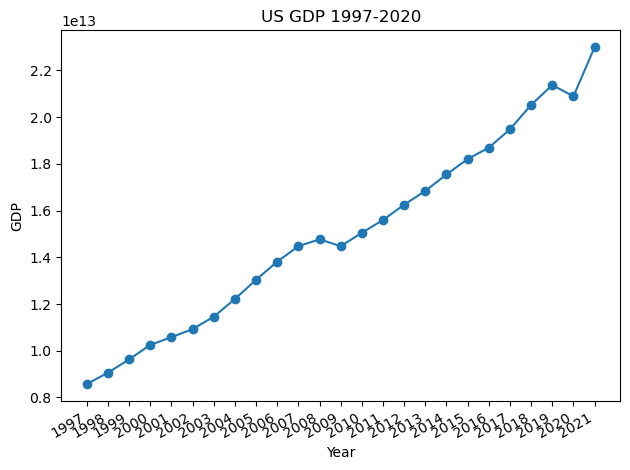

In [ ]:
UGDP_period = USGPD['Year'].sort_values()
GDP= USGPD['GDP']

plt.plot_date(UGDP_period, GDP, linestyle='solid')

plt.gcf().autofmt_xdate()


plt.title('US GDP 1997-2020')
plt.xlabel('Year')
plt.ylabel('GDP')

plt.tight_layout()

In [ ]:
USGPD=USGPD.drop(['Year','Month'], axis=1)

#### Monthly Retail Trade

In [ ]:
retail = pd.read_excel('Retail and food Services Sales.xlsx')
retail.head()

,Year,Month,Label,Retail and food Services Sales total
0,1997,Jan,1997 Jan,200389.0
1,1997,Feb,1997 Feb,197556.0
2,1997,Mar,1997 Mar,225133.0
3,1997,Apr,1997 Apr,220329.0
4,1997,May,1997 May,234190.0


In [ ]:
retail['Period']=retail.apply(lambda _: '', axis=1)

In [ ]:
Month = {
    'Jan': 'M01',
    'Feb': 'M02',
    'Mar': 'M03',
    'Apr': 'M04',
    'May': 'M05',
    'Jun': 'M06',
    'Jul': 'M07',
    'Aug': 'M08',
    'Sep': 'M09',
    'Oct': 'M10',
    'Nov': 'M11',
    'Dec': 'M12',
}
retail['Period'] = retail['Month'].map(Month)


In [ ]:
retail['datetime'] =  pd.to_datetime(retail['Label'], format='%Y %b')

In [ ]:
retail = retail.sort_values('datetime')

In [ ]:
retail['Period'].value_counts()

M01    26
M02    26
M03    26
M04    26
M05    26
M06    26
M07    26
M08    26
M09    26
M10    26
M11    25
M12    25
Name: Period, dtype: int64

In [ ]:
retail['Year']=pd.to_datetime(retail['Year'], format='%Y')

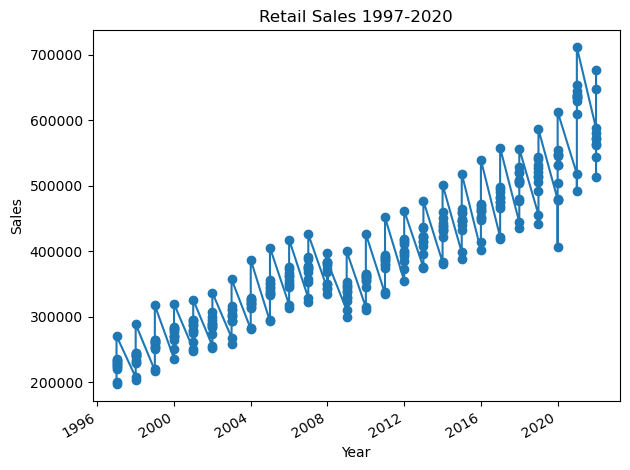

In [ ]:
retail_period = retail['Year']
totals= retail['Retail and food Services Sales total']

plt.plot_date(retail_period, totals, linestyle='solid')

plt.gcf().autofmt_xdate()


plt.title('Retail Sales 1997-2020')
plt.xlabel('Year')
plt.ylabel('Sales')

plt.tight_layout()

In [ ]:
retail = retail.drop(['Year','Month'], axis=1)

In [ ]:
retail

,Label,Retail and food Services Sales total,Period,datetime
0,1997 Jan,200389.000000,M01,1997-01-01
1,1997 Feb,197556.000000,M02,1997-02-01
2,1997 Mar,225133.000000,M03,1997-03-01
3,1997 Apr,220329.000000,M04,1997-04-01
4,1997 May,234190.000000,M05,1997-05-01
...,...,...,...,...
305,2022 Jun,561648.333333,M06,2022-06-01
306,2022 Jul,571195.333333,M07,2022-07-01
307,2022 Aug,573686.000000,M08,2022-08-01
308,2022 Sep,544501.333333,M09,2022-09-01


In [ ]:
#Dropping unnecesary rows. Anything before May 1997
retail = retail.drop([0,1,2,3])

In [ ]:
retail

,Label,Retail and food Services Sales total,Period,datetime
4,1997 May,234190.000000,M05,1997-05-01
5,1997 Jun,227365.000000,M06,1997-06-01
6,1997 Jul,231521.000000,M07,1997-07-01
7,1997 Aug,235252.000000,M08,1997-08-01
8,1997 Sep,222807.000000,M09,1997-09-01
...,...,...,...,...
305,2022 Jun,561648.333333,M06,2022-06-01
306,2022 Jul,571195.333333,M07,2022-07-01
307,2022 Aug,573686.000000,M08,2022-08-01
308,2022 Sep,544501.333333,M09,2022-09-01


In [ ]:
retail['Period'].value_counts()

M05    26
M06    26
M07    26
M08    26
M09    26
M10    26
M11    25
M12    25
M01    25
M02    25
M03    25
M04    25
Name: Period, dtype: int64

#### CPI for All Urban Consumers (CPI-U) from 1997 to 2022

In [ ]:
cpi = pd.read_excel('DataFinder20221111100826.xlsx')
cpi.head()

,Year,Period,Label,Observation Value
0,1997,M01,1997 Jan,159.4
1,1997,M02,1997 Feb,159.7
2,1997,M03,1997 Mar,159.8
3,1997,M04,1997 Apr,159.9
4,1997,M05,1997 May,159.9


In [ ]:
#Dropping unnecesary rows. Anything before May 1997
cpi= cpi.drop([0,1,2,3])

In [ ]:
# Chaining columns to appropiate name
cpi.rename(columns={'Observation Value': 'CPI'})

,Year,Period,Label,CPI
4,1997,M05,1997 May,159.900
5,1997,M06,1997 Jun,160.200
6,1997,M07,1997 Jul,160.400
7,1997,M08,1997 Aug,160.800
8,1997,M09,1997 Sep,161.200
...,...,...,...,...
305,2022,M06,2022 Jun,295.328
306,2022,M07,2022 Jul,295.271
307,2022,M08,2022 Aug,295.620
308,2022,M09,2022 Sep,296.761


In [ ]:
cpi['datetime'] =  pd.to_datetime(cpi['Label'], format='%Y %b')

In [ ]:
cpi = cpi.sort_values('datetime')

In [ ]:
cpi['Period'].value_counts()

M05    26
M06    26
M07    26
M08    26
M09    26
M10    26
M11    25
M12    25
M01    25
M02    25
M03    25
M04    25
Name: Period, dtype: int64

In [ ]:
cpi['Year']=pd.to_datetime(cpi['Year'], format='%Y')

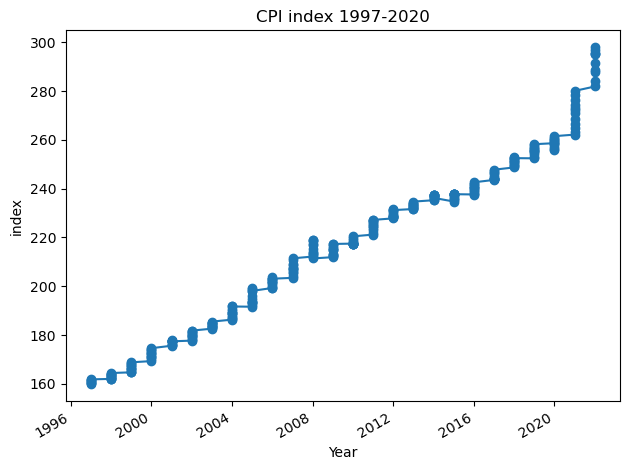

In [ ]:
cpi_period = cpi['Year']
value= cpi['Observation Value']

plt.plot_date(cpi_period, value, linestyle='solid')

plt.gcf().autofmt_xdate()


plt.title('CPI index 1997-2020')
plt.xlabel('Year')
plt.ylabel('index')

plt.tight_layout()

In [ ]:
cpi = cpi.drop(['Year'], axis=1)

In [ ]:
cpi

,Period,Label,Observation Value,datetime
4,M05,1997 May,159.900,1997-05-01
5,M06,1997 Jun,160.200,1997-06-01
6,M07,1997 Jul,160.400,1997-07-01
7,M08,1997 Aug,160.800,1997-08-01
8,M09,1997 Sep,161.200,1997-09-01
...,...,...,...,...
305,M06,2022 Jun,295.328,2022-06-01
306,M07,2022 Jul,295.271,2022-07-01
307,M08,2022 Aug,295.620,2022-08-01
308,M09,2022 Sep,296.761,2022-09-01


In [ ]:
cpi['Period'].value_counts()

M05    26
M06    26
M07    26
M08    26
M09    26
M10    26
M11    25
M12    25
M01    25
M02    25
M03    25
M04    25
Name: Period, dtype: int64

#### Unemployment Rate in the US from 1997 to 2022

In [ ]:
df = pd.read_excel('Unemployment Rate.xlsx')
df.head()

,Year,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
0,1997,5.3,5.2,5.2,5.1,4.9,5.0,4.9,4.8,4.9,4.7,4.6,4.7
1,1998,4.6,4.6,4.7,4.3,4.4,4.5,4.5,4.5,4.6,4.5,4.4,4.4
2,1999,4.3,4.4,4.2,4.3,4.2,4.3,4.3,4.2,4.2,4.1,4.1,4.0
3,2000,4.0,4.1,4.0,3.8,4.0,4.0,4.0,4.1,3.9,3.9,3.9,3.9
4,2001,4.2,4.2,4.3,4.4,4.3,4.5,4.6,4.9,5.0,5.3,5.5,5.7


In [ ]:
unemprate = pd.melt(df, id_vars=["Year"], var_name='Month', value_name='unemplomentrate')
unemprate

,Year,Month,unemplomentrate
0,1997,Jan,5.3
1,1998,Jan,4.6
2,1999,Jan,4.3
3,2000,Jan,4.0
4,2001,Jan,4.2
...,...,...,...
307,2018,Dec,3.9
308,2019,Dec,3.6
309,2020,Dec,6.7
310,2021,Dec,3.9


In [ ]:
unemprate["Label"] = unemprate["Year"].astype(str) + " " +unemprate["Month"]

In [ ]:
unemprate['Period']=unemprate.apply(lambda _: '', axis=1)

In [ ]:
Month = {
    'Jan': 'M01',
    'Feb': 'M02',
    'Mar': 'M03',
    'Apr': 'M04',
    'May': 'M05',
    'Jun': 'M06',
    'Jul': 'M07',
    'Aug': 'M08',
    'Sep': 'M09',
    'Oct': 'M10',
    'Nov': 'M11',
    'Dec': 'M12',
}
unemprate['Period'] = unemprate['Month'].map(Month)

In [ ]:
unemprate['datetime'] =  pd.to_datetime(unemprate['Label'], format='%Y %b')

In [ ]:
unemprate= unemprate.sort_values('datetime')

In [ ]:
unemprate['Period'].value_counts()

M01    26
M02    26
M03    26
M04    26
M05    26
M06    26
M07    26
M08    26
M09    26
M10    26
M11    26
M12    26
Name: Period, dtype: int64

In [ ]:
unemprate['Year']=pd.to_datetime(unemprate['Year'], format='%Y')

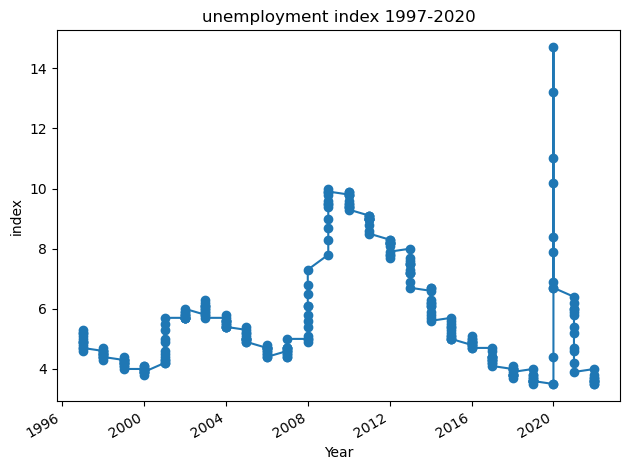

In [ ]:
unemp_period = unemprate['Year']
value1= unemprate['unemplomentrate']

plt.plot_date(unemp_period, value1, linestyle='solid')

plt.gcf().autofmt_xdate()


plt.title('unemployment index 1997-2020')
plt.xlabel('Year')
plt.ylabel('index')

plt.tight_layout()

In [ ]:
unemprate=unemprate.drop(['Year','Month'], axis=1)

In [ ]:
unemprate

,unemplomentrate,Label,Period,datetime
0,5.3,1997 Jan,M01,1997-01-01
26,5.2,1997 Feb,M02,1997-02-01
52,5.2,1997 Mar,M03,1997-03-01
78,5.1,1997 Apr,M04,1997-04-01
104,4.9,1997 May,M05,1997-05-01
...,...,...,...,...
207,3.7,2022 Aug,M08,2022-08-01
233,3.5,2022 Sep,M09,2022-09-01
259,3.7,2022 Oct,M10,2022-10-01
285,NaN,2022 Nov,M11,2022-11-01


In [ ]:
unemprate= unemprate.drop([0,26,52,78])

In [ ]:
unemprate['Period'].value_counts()

M05    26
M06    26
M07    26
M08    26
M09    26
M10    26
M11    26
M12    26
M01    25
M02    25
M03    25
M04    25
Name: Period, dtype: int64

In [ ]:
unemprate

,unemplomentrate,Label,Period,datetime
104,4.9,1997 May,M05,1997-05-01
130,5.0,1997 Jun,M06,1997-06-01
156,4.9,1997 Jul,M07,1997-07-01
182,4.8,1997 Aug,M08,1997-08-01
208,4.9,1997 Sep,M09,1997-09-01
...,...,...,...,...
207,3.7,2022 Aug,M08,2022-08-01
233,3.5,2022 Sep,M09,2022-09-01
259,3.7,2022 Oct,M10,2022-10-01
285,NaN,2022 Nov,M11,2022-11-01


#### Inflation Rate from 1997 to 2022

In [ ]:
df1 = pd.read_excel('US Inflation Rate.xlsx')
df1.head()

,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,AVE
0,1997,3.0,3.0,2.8,2.5,2.2,2.3,2.2,2.2,2.2,2.1,1.8,1.7,2.3
1,1998,1.6,1.4,1.4,1.4,1.7,1.7,1.7,1.6,1.5,1.5,1.5,1.6,1.6
2,1999,1.7,1.6,1.7,2.3,2.1,2.0,2.1,2.3,2.6,2.6,2.6,2.7,2.2
3,2000,2.7,3.2,3.8,3.1,3.2,3.7,3.7,3.4,3.5,3.4,3.4,3.4,3.4
4,2001,3.7,3.5,2.9,3.3,3.6,3.2,2.7,2.7,2.6,2.1,1.9,1.6,2.8


In [ ]:
inflation = pd.melt(df, id_vars=["Year"], var_name='Month', value_name='Inflation Rate')
inflation

,Year,Month,Inflation Rate
0,1997,Jan,5.3
1,1998,Jan,4.6
2,1999,Jan,4.3
3,2000,Jan,4.0
4,2001,Jan,4.2
...,...,...,...
307,2018,Dec,3.9
308,2019,Dec,3.6
309,2020,Dec,6.7
310,2021,Dec,3.9


In [ ]:
inflation["Label"] = inflation["Year"].astype(str) + " " +inflation["Month"]

In [ ]:
inflation['Period']= inflation.apply(lambda _: '', axis=1)

In [ ]:
Month = {
    'Jan': 'M01',
    'Feb': 'M02',
    'Mar': 'M03',
    'Apr': 'M04',
    'May': 'M05',
    'Jun': 'M06',
    'Jul': 'M07',
    'Aug': 'M08',
    'Sep': 'M09',
    'Oct': 'M10',
    'Nov': 'M11',
    'Dec': 'M12',
}
inflation['Period'] = inflation['Month'].map(Month)


In [ ]:
inflation['datetime'] =  pd.to_datetime(inflation['Label'], format='%Y %b')

In [ ]:
inflation= inflation.sort_values('datetime')

In [ ]:
inflation['Period'].value_counts()

M01    26
M02    26
M03    26
M04    26
M05    26
M06    26
M07    26
M08    26
M09    26
M10    26
M11    26
M12    26
Name: Period, dtype: int64

In [ ]:
inflation['Year']=pd.to_datetime(inflation['Year'], format='%Y')

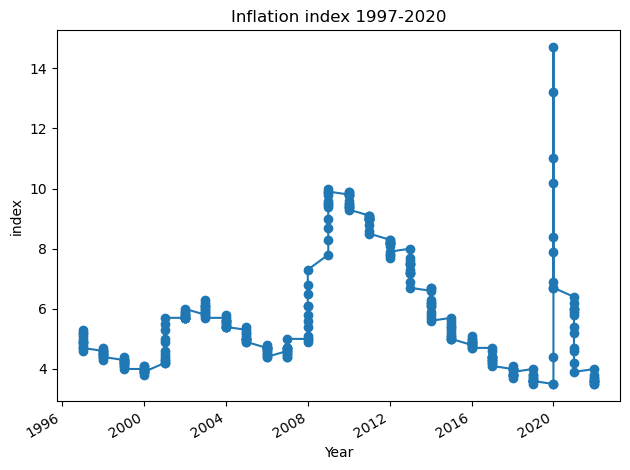

In [ ]:
i_period = inflation['Year']
valuei= inflation['Inflation Rate']

plt.plot_date(i_period, valuei, linestyle='solid')

plt.gcf().autofmt_xdate()


plt.title('Inflation index 1997-2020')
plt.xlabel('Year')
plt.ylabel('index')

plt.tight_layout()

It is interesting to note the similarities between unemploment and inflation charts

In [ ]:
inflation= inflation.drop(['Year','Month'], axis=1)

In [ ]:
inflation

,Inflation Rate,Label,Period,datetime
0,5.3,1997 Jan,M01,1997-01-01
26,5.2,1997 Feb,M02,1997-02-01
52,5.2,1997 Mar,M03,1997-03-01
78,5.1,1997 Apr,M04,1997-04-01
104,4.9,1997 May,M05,1997-05-01
...,...,...,...,...
207,3.7,2022 Aug,M08,2022-08-01
233,3.5,2022 Sep,M09,2022-09-01
259,3.7,2022 Oct,M10,2022-10-01
285,NaN,2022 Nov,M11,2022-11-01


In [ ]:
inflation= inflation.drop([0,26,52,78])

In [ ]:
inflation

,Inflation Rate,Label,Period,datetime
104,4.9,1997 May,M05,1997-05-01
130,5.0,1997 Jun,M06,1997-06-01
156,4.9,1997 Jul,M07,1997-07-01
182,4.8,1997 Aug,M08,1997-08-01
208,4.9,1997 Sep,M09,1997-09-01
...,...,...,...,...
207,3.7,2022 Aug,M08,2022-08-01
233,3.5,2022 Sep,M09,2022-09-01
259,3.7,2022 Oct,M10,2022-10-01
285,NaN,2022 Nov,M11,2022-11-01


### Now we can merge all datasets

In [ ]:
newdf = USGPD.merge(retail, how='right', on =['Label', 'Period','datetime'])

In [ ]:
newdf

,GDP,Label,Period,datetime,Retail and food Services Sales total
0,8.577554e+12,1997 May,M05,1997-05-01,234190.000000
1,NaN,1997 Jun,M06,1997-06-01,227365.000000
2,NaN,1997 Jul,M07,1997-07-01,231521.000000
3,NaN,1997 Aug,M08,1997-08-01,235252.000000
4,NaN,1997 Sep,M09,1997-09-01,222807.000000
...,...,...,...,...,...
301,NaN,2022 Jun,M06,2022-06-01,561648.333333
302,NaN,2022 Jul,M07,2022-07-01,571195.333333
303,NaN,2022 Aug,M08,2022-08-01,573686.000000
304,NaN,2022 Sep,M09,2022-09-01,544501.333333


In [ ]:
newdf = newdf.merge(cpi, how='right', on =['Label', 'Period','datetime'])

In [ ]:
newdf = newdf.merge(unemprate, how='inner', on =['Label', 'Period','datetime'])

In [ ]:
newdf = newdf.merge(inflation, how='inner', on =['Label', 'Period','datetime'])

#### Dealing with null values

In [ ]:
newdf.isnull().sum()

GDP                                     281
Label                                     0
Period                                    0
datetime                                  0
Retail and food Services Sales total      0
Observation Value                         0
unemplomentrate                           0
Inflation Rate                            0
dtype: int64

##### GDP: We are going to assume that the GDP is stable through the entire year

In [ ]:
gdp_new=newdf[['GDP','datetime']]

In [ ]:
gdp_new = gdp_new.fillna(method='ffill')

In [ ]:
newdf=newdf.merge(gdp_new, how='left', on=['datetime'])

In [ ]:
newdf = newdf.drop(['GDP_x'],axis=1)

In [ ]:
newdf= newdf.rename(columns={'GDP_y': 'GDP', 'datetime':'Date'})

In [ ]:
# Fixing first date to match next dataset and not introduce unnecessary NaN values
newdf.loc[0,'Date']='1997-05-15'

In [ ]:
newdf = newdf.set_index('Date')

In [ ]:
# Let's take care of the decimals in Retail and food Services Sales total column
newdf = newdf.round({'Retail and food Services Sales total': 2})

In [ ]:
amzn.head(3)

,Open,High,Low,Close,Adj Close,Volume,MarktCap,MA50,MA200,returns
Date,,,,,,,,,,
1997-05-15,0.121875,0.125000,0.096354,0.097917,0.097917,1443120000,1.758803e+08,NaN,NaN,NaN
1997-05-16,0.098438,0.098958,0.085417,0.086458,0.086458,294000000,2.894077e+07,NaN,NaN,-0.117028
1997-05-19,0.088021,0.088542,0.081250,0.085417,0.085417,122136000,1.075053e+07,NaN,NaN,-0.012040


In [ ]:
newdf.head(3)

,Label,Period,Retail and food Services Sales total,Observation Value,unemplomentrate,Inflation Rate,GDP
Date,,,,,,,
1997-05-15,1997 May,M05,234190.0,159.9,4.9,4.9,8.577554e+12
1997-06-01,1997 Jun,M06,227365.0,160.2,5.0,5.0,8.577554e+12
1997-07-01,1997 Jul,M07,231521.0,160.4,4.9,4.9,8.577554e+12


In [ ]:
a =(newdf['Period']=='M01')
newdf[a]['Label']

Date
1998-01-01    1998 Jan
1999-01-01    1999 Jan
2000-01-01    2000 Jan
2001-01-01    2001 Jan
2002-01-01    2002 Jan
2003-01-01    2003 Jan
2004-01-01    2004 Jan
2005-01-01    2005 Jan
2006-01-01    2006 Jan
2007-01-01    2007 Jan
2008-01-01    2008 Jan
2009-01-01    2009 Jan
2010-01-01    2010 Jan
2011-01-01    2011 Jan
2012-01-01    2012 Jan
2013-01-01    2013 Jan
2014-01-01    2014 Jan
2015-01-01    2015 Jan
2016-01-01    2016 Jan
2017-01-01    2017 Jan
2018-01-01    2018 Jan
2019-01-01    2019 Jan
2020-01-01    2020 Jan
2021-01-01    2021 Jan
2022-01-01    2022 Jan
Name: Label, dtype: object

In [ ]:
new_amazon = pd.concat([newdf, amzn], axis=1)

In [ ]:
new_amazon

,Label,Period,Retail and food Services Sales total,Observation Value,unemplomentrate,Inflation Rate,GDP,Open,High,Low,Close,Adj Close,Volume,MarktCap,MA50,MA200,returns
Date,,,,,,,,,,,,,,,,,
1997-05-15,1997 May,M05,234190.0,159.9,4.9,4.9,8.577554e+12,0.121875,0.125000,0.096354,0.097917,0.097917,1.443120e+09,1.758803e+08,NaN,NaN,NaN
1997-05-16,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.098438,0.098958,0.085417,0.086458,0.086458,2.940000e+08,2.894077e+07,NaN,NaN,-0.117028
1997-05-19,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.088021,0.088542,0.081250,0.085417,0.085417,1.221360e+08,1.075053e+07,NaN,NaN,-0.012040
1997-05-20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.086458,0.087500,0.081771,0.081771,0.081771,1.093440e+08,9.453663e+06,NaN,NaN,-0.042685
1997-05-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.081771,0.082292,0.068750,0.071354,0.071354,3.770640e+08,3.083290e+07,NaN,NaN,-0.127392
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2022-11-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,92.470001,93.500000,89.019997,89.300003,89.300003,1.366833e+08,1.263910e+10,118.7850,130.924348,-0.030612
2022-11-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,91.489998,92.440002,88.040001,90.980003,90.980003,1.289999e+08,1.180220e+10,117.9096,130.597968,0.018813
2022-11-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,91.949997,92.099998,89.040001,90.529999,90.529999,7.749570e+07,7.125729e+09,117.0176,130.307968,-0.004946


In [ ]:
new_amazon = new_amazon.fillna(method='ffill')

In [ ]:
new_amazon['Period'].value_counts()

M10    587
M08    583
M06    563
M07    557
M03    556
M05    546
M09    539
M12    536
M01    530
M04    524
M11    518
M02    486
Name: Period, dtype: int64

In [ ]:
new_amazon = new_amazon.fillna(0)

In [ ]:
# Saving file to a new csv
new_amazon.to_csv('newamazon.csv')

Now that the dataset is created we can move to the next notebook